In [14]:
from google.colab import files  # Imports the file-upload tool for Google Colab
uploaded = files.upload()  # Opens a dialog to upload Social_Network_Ads.csv

Saving Social_Network_Ads.csv to Social_Network_Ads (1).csv


In [15]:
import pandas as pd  # Imports pandas to read and process tabular data
import matplotlib.pyplot as plt  # Imports Matplotlib to create comparison charts

from sklearn.model_selection import train_test_split  # Imports the function for splitting training and testing data
from sklearn.compose import ColumnTransformer  # Imports a tool to preprocess different column types
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Imports feature scaling and categorical encoding
from sklearn.pipeline import Pipeline  # Imports Pipeline to combine preprocessing and model training
from sklearn.linear_model import LogisticRegression  # Imports the Logistic Regression classifier
from sklearn.tree import DecisionTreeClassifier  # Imports the Decision Tree classifier
from sklearn.ensemble import RandomForestClassifier  # Imports the Random Forest classifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report  # Imports classification evaluation metrics

In [16]:
df = pd.read_csv("Social_Network_Ads.csv")  # Reads the uploaded CSV dataset into a DataFrame
print("Dataset shape:", df.shape)  # Displays the number of rows and columns
print(df.head())  # Displays the first five records
print(df.isnull().sum())  # Checks for missing values in every column
print(df["Purchased"].value_counts())  # Displays the number of customers in each target class

Dataset shape: (400, 5)
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64
Purchased
0    257
1    143
Name: count, dtype: int64


In [17]:
X = df[["Gender", "Age", "EstimatedSalary"]]  # Selects the customer features used for prediction and excludes User ID
y = df["Purchased"]  # Selects Purchased as the target variable

categorical_cols = ["Gender"]  # Identifies Gender as a categorical feature
numerical_cols = ["Age", "EstimatedSalary"]  # Identifies Age and EstimatedSalary as numerical features

print("Input features:", X.columns.tolist())  # Displays the input feature names
print("Target variable: Purchased")  # Displays the name of the variable to predict

Input features: ['Gender', 'Age', 'EstimatedSalary']
Target variable: Purchased


In [18]:
X_train, X_test, y_train, y_test = train_test_split(  # Splits input features and target labels together
    X, y, test_size=0.20, random_state=42, stratify=y  # Reserves 20% for testing and preserves class proportions
)  # Finishes the train-test split

print("Training records:", len(X_train))  # Displays the number of training records
print("Testing records:", len(X_test))  # Displays the number of testing records

Training records: 320
Testing records: 80


In [19]:
preprocessor = ColumnTransformer([  # Creates a preprocessing system for different feature types
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),  # Converts Gender into numeric indicator columns
    ("numerical", StandardScaler(), numerical_cols)  # Standardizes Age and EstimatedSalary using training data statistics
])  # Finishes the preprocessing configuration

In [20]:
models = {  # Creates a dictionary to store the three classifiers

    "Logistic Regression": LogisticRegression(  # Creates the Logistic Regression model
        max_iter=1000,  # Allows enough iterations for model convergence
        random_state=42  # Sets a reproducible random seed where applicable
    ),  # Finishes the Logistic Regression model definition

    "Decision Tree": DecisionTreeClassifier(  # Creates the Decision Tree model
        max_depth=5,  # Limits the tree depth to help control overfitting
        random_state=42  # Makes the tree-building process reproducible
    ),  # Finishes the Decision Tree model definition

    "Random Forest": RandomForestClassifier(  # Creates the Random Forest model
        n_estimators=100,  # Uses 100 decision trees in the forest
        max_depth=5,  # Limits the depth of each tree
        random_state=42  # Makes the model reproducible
    )  # Finishes the Random Forest model definition

}  # Finishes the dictionary of classification algorithms

In [21]:
results = []  # Creates a list to store the evaluation scores of all models
trained_models = {}  # Creates a dictionary to save the trained pipelines

for name, model in models.items():  # Iterates through all three classification algorithms

    pipeline = Pipeline([  # Combines preprocessing and classification into one pipeline
        ("preprocessing", preprocessor),  # Encodes Gender and scales numerical features
        ("classifier", model)  # Adds the current classification algorithm
    ])  # Finishes the pipeline definition

    pipeline.fit(X_train, y_train)  # Trains the model using the training dataset
    y_pred = pipeline.predict(X_test)  # Predicts the purchase class for each test record

    accuracy = accuracy_score(y_test, y_pred)  # Calculates the proportion of correct predictions
    precision = precision_score(y_test, y_pred, zero_division=0)  # Measures how many predicted purchases were actually purchases
    recall = recall_score(y_test, y_pred, zero_division=0)  # Measures how many actual purchases were correctly identified
    f1 = f1_score(y_test, y_pred, zero_division=0)  # Calculates the harmonic mean of precision and recall
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])  # Creates a confusion matrix for No and Yes predictions

    results.append({  # Stores the current algorithm's evaluation scores
        "Algorithm": name,  # Records the model name
        "Accuracy (%)": accuracy * 100,  # Stores accuracy as a percentage
        "Precision (%)": precision * 100,  # Stores precision as a percentage
        "Recall (%)": recall * 100,  # Stores recall as a percentage
        "F1 Score (%)": f1 * 100  # Stores F1 score as a percentage
    })  # Finishes storing the scores

    trained_models[name] = pipeline  # Saves the fitted pipeline for future predictions

    print("\nAlgorithm:", name)  # Prints the current algorithm's name
    print(f"Accuracy: {accuracy * 100:.2f}%")  # Displays the accuracy percentage
    print(f"Precision: {precision * 100:.2f}%")  # Displays the precision percentage
    print(f"Recall: {recall * 100:.2f}%")  # Displays the recall percentage
    print(f"F1 Score: {f1 * 100:.2f}%")  # Displays the F1 score percentage
    print("Confusion Matrix:\n", cm)  # Displays correct and incorrect predictions
    print(classification_report(y_test, y_pred, target_names=["Not Purchased", "Purchased"], zero_division=0))  # Displays detailed class-wise evaluation


Algorithm: Logistic Regression
Accuracy: 81.25%
Precision: 81.82%
Recall: 62.07%
F1 Score: 70.59%
Confusion Matrix:
 [[47  4]
 [11 18]]
               precision    recall  f1-score   support

Not Purchased       0.81      0.92      0.86        51
    Purchased       0.82      0.62      0.71        29

     accuracy                           0.81        80
    macro avg       0.81      0.77      0.78        80
 weighted avg       0.81      0.81      0.81        80


Algorithm: Decision Tree
Accuracy: 82.50%
Precision: 74.19%
Recall: 79.31%
F1 Score: 76.67%
Confusion Matrix:
 [[43  8]
 [ 6 23]]
               precision    recall  f1-score   support

Not Purchased       0.88      0.84      0.86        51
    Purchased       0.74      0.79      0.77        29

     accuracy                           0.82        80
    macro avg       0.81      0.82      0.81        80
 weighted avg       0.83      0.82      0.83        80


Algorithm: Random Forest
Accuracy: 90.00%
Precision: 83.87%
Recal

In [22]:
results_df = pd.DataFrame(results)  # Converts the evaluation results into a comparison table
results_df = results_df.sort_values("Accuracy (%)", ascending=False)  # Ranks the algorithms by highest test accuracy
display(results_df.round(2))  # Displays the comparison table with two decimal places

,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
2,Random Forest,90.00,83.87,89.66,86.67
1,Decision Tree,82.50,74.19,79.31,76.67
0,Logistic Regression,81.25,81.82,62.07,70.59


In [23]:
best_row = results_df.iloc[0]  # Selects the first row after sorting by test accuracy
best_name = best_row["Algorithm"]  # Retrieves the name of the highest-accuracy algorithm
best_accuracy = best_row["Accuracy (%)"]  # Retrieves its test accuracy

print("BEST CLASSIFICATION ALGORITHM:", best_name)  # Displays the winning algorithm
print(f"Highest Test Accuracy: {best_accuracy:.2f}%")  # Displays the highest accuracy percentage
print(f"Precision: {best_row['Precision (%)']:.2f}%")  # Displays the winning model's precision
print(f"Recall: {best_row['Recall (%)']:.2f}%")  # Displays the winning model's recall
print(f"F1 Score: {best_row['F1 Score (%)']:.2f}%")  # Displays the winning model's F1 score

BEST CLASSIFICATION ALGORITHM: Random Forest
Highest Test Accuracy: 90.00%
Precision: 83.87%
Recall: 89.66%
F1 Score: 86.67%


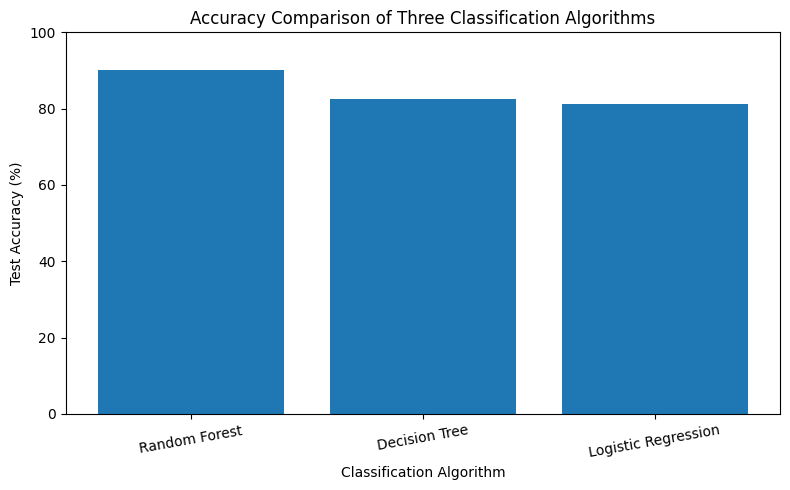

In [24]:
plt.figure(figsize=(8, 5))  # Creates a figure with a suitable size
plt.bar(results_df["Algorithm"], results_df["Accuracy (%)"])  # Draws a bar for each model's test accuracy
plt.xlabel("Classification Algorithm")  # Labels the horizontal axis
plt.ylabel("Test Accuracy (%)")  # Labels the vertical axis
plt.title("Accuracy Comparison of Three Classification Algorithms")  # Adds a descriptive chart title
plt.ylim(0, 100)  # Sets the accuracy axis from 0% to 100%
plt.xticks(rotation=10)  # Rotates algorithm labels slightly for readability
plt.tight_layout()  # Adjusts the layout to prevent overlapping labels
plt.show()  # Displays the accuracy comparison chart

**Title: Comparison of Three Classification Algorithms Using Social Network Ads Dataset**

**Objective:** To implement Logistic Regression, Decision Tree, and Random Forest classifiers and compare their performance in predicting customer purchases.

**Methodology:** The dataset was divided into 80% training data and 20% testing data. Gender was encoded, and numerical features were standardized. All three algorithms were trained using the training set and evaluated on the unseen test set.

**Evaluation:** Accuracy, precision, recall, F1 score, and confusion matrices were calculated for each model.

**Result:** The model with the highest test accuracy was selected as the best-performing classifier. Its performance was compared with the other two algorithms.

**Conclusion:** Classification algorithms can predict whether customers are likely to purchase a product based on their age, gender, and estimated salary. The best-performing algorithm was identified using the experimental test results.